# Анализ графовых представлений

Проверяем, какие ручные признаки можно восстановить из эмбеддингов HeteroGNN с помощью Ridge. Сравниваем со степенью узла, случайными эмбеддингами и средним. Затем оцениваем качество HeteroGNN, LightGCN и RRF для пользователей с разной длиной истории. Даты: 21 июня, 19 июля и 2 августа 2021 года.

In [1]:
import pandas as pd
import numpy as np

interactions = pd.read_csv('data_original/interactions.csv', parse_dates=['last_watch_dt'])
items = pd.read_csv('data_original/items.csv').reset_index(drop=True)
item_ids = pd.Index(items['item_id'])

items[['item_id','genres','actors','directors','countries']].head()

,item_id,genres,actors,directors,countries
0,10711,"драмы, зарубежные, детективы, мелодрамы","Адольфо Фернандес, Ана Фернандес, Дарио Гранди...",Педро Альмодовар,Испания
1,2508,"зарубежные, приключения, комедии","Адам Палли, Брайан Хаски, Дж.Б. Смув, Джейсон ...",Скот Армстронг,США
2,10716,"криминал, зарубежные, триллеры, боевики, комедии","Адриан Холмс, Даррен Шалави, Джерри Вассерман,...",Адам П. Калтраро,Канада
3,7868,"драмы, зарубежные, мелодрамы","Александра Риддлстон-Барретт, Джеральдин Джейм...",Эндрю Хэй,Великобритания
4,16268,"драмы, спорт, советские, мелодрамы","Александр Абдулов, Александр Демьяненко, Алекс...",Виктор Садовский,СССР


In [2]:
metadata = {}
meta_size = 0

for field in ('genres', 'actors', 'directors', 'countries'):
    values = items[field].fillna("").astype(str)
    tokens = values.map(lambda s: sorted({v.strip() for v in s.split(",") if v.strip()}))
    pairs = tokens.explode().dropna()
    labels, names = pd.factorize(pairs, sort=True)
    metadata[field] = {
        "item": pairs.index.to_numpy(dtype=np.int32),
        "attr": labels.astype(np.int32) + meta_size,
        "start": meta_size,
        "end": meta_size + len(names),
    }
    meta_size += len(names)

[(field, info["end"] - info["start"], len(info["item"])) for field, info in metadata.items()]

[('genres', 95, 40637),
 ('actors', 61883, 139670),
 ('directors', 8838, 17810),
 ('countries', 91, 18258)]

In [3]:
from scipy import sparse
import torch

def history_graph(t):
    h = interactions.loc[interactions["last_watch_dt"] < t]
    user_codes, user_ids = pd.factorize(h["user_id"], sort=True)
    product_codes = item_ids.get_indexer(h["item_id"])
    return h, user_ids, user_codes.astype(np.int32), product_codes.astype(np.int32)

In [4]:
def normalized_relation_cpu(src, dst, n_nodes):
    src = np.asarray(src, dtype=np.int64)
    dst = np.asarray(dst, dtype=np.int64)
    degree = np.bincount(np.r_[src, dst], minlength=n_nodes).astype(np.float32)
    weights = 1 / np.sqrt(np.maximum(degree[src] * degree[dst], 1))
    return sparse.csr_matrix(
        (np.r_[weights, weights], (np.r_[src, dst], np.r_[dst, src])),
        shape=(n_nodes, n_nodes), dtype=np.float32
    )

In [5]:
def hetero_embeddings_cpu(state, users, products, n_users):
    n_items = len(item_ids)
    n_nodes = n_users + n_items + meta_size
    x = state["emb.weight"].detach().numpy().astype(np.float32)
    gates = torch.sigmoid(state["relation_logits"]).numpy()

    adjs = {"interaction": normalized_relation_cpu(users, n_users + products, n_nodes)}
    presence = []
    for field, info in metadata.items():
        adjs[field] = normalized_relation_cpu(
            n_users + info["item"], n_users + n_items + info["attr"], n_nodes
        )
        presence.append(np.bincount(info["item"], minlength=n_items) > 0)
    denom = 1 + (gates[:, None] * np.stack(presence)).sum(axis=0)

    result = x.copy()
    a, b = n_users, n_users + n_items
    for _ in range(3):
        ui = adjs["interaction"] @ x
        item_msg = ui[a:b].copy()
        attrs = []
        for k, (field, info) in enumerate(metadata.items()):
            msg = adjs[field] @ x
            item_msg += gates[k] * msg[a:b]
            attrs.append(msg[b + info["start"]:b + info["end"]].copy())
            del msg
        x = np.concatenate([ui[:a], item_msg / denom[:, None], *attrs])
        result += x
    return result / (3 + 1)

In [6]:
def light_embeddings_cpu(state, users, products, n_users):
    n_items = len(item_ids)
    x = state["emb.weight"].detach().numpy().astype(np.float32)
    adj = normalized_relation_cpu(users, n_users + products, len(x))
    result = x.copy()
    for _ in range(3):
        x = adj @ x
        result += x
    return result / (3 + 1)

In [7]:
from pathlib import Path
import gc

probe_dir = Path('results/kion_graph_probing')
probe_dir.mkdir(parents=True, exist_ok=True)

In [8]:
def load_embeddings(t, user_ids, users, products):
    n_users = len(user_ids)
    stamp = f"{t:%Y%m%d}"
    h_cache = probe_dir / f"hetero_emb_{stamp}.npy"
    l_cache = probe_dir / f"light_emb_{stamp}.npy"
    degree = np.bincount(products, minlength=len(item_ids))

    has_metadata = np.zeros(len(item_ids), dtype=bool)
    for info in metadata.values():
        has_metadata[info["item"]] = True
    available = (degree > 0) | has_metadata

    for cache, folder, forward in (
        (h_cache, Path('results/heterolightgcn_full_history'), hetero_embeddings_cpu),
        (l_cache, Path('results/lightgcn_full_history'), light_embeddings_cpu),
    ):
        if cache.exists():
            continue
        checkpoint = torch.load(folder / f"model_{stamp}.pt", map_location="cpu", weights_only=False)
        emb = forward(checkpoint["model"], users, products, n_users)
        np.save(cache, emb.astype(np.float32))
        del checkpoint, emb
        gc.collect()

    return np.load(h_cache, mmap_mode="r"), np.load(l_cache, mmap_mode="r"), available

In [9]:
import pyarrow.parquet as pq
import pyarrow as pa
import pyarrow.compute as pc

In [10]:
def replay_user_ids(t):
    path = Path('data_processed/replay') / f"{t:%Y-%m-%d}.parquet"
    parquet = pq.ParquetFile(path)
    pieces = []
    tail = np.empty(0, dtype=np.int64)
    for batch in parquet.iter_batches(batch_size=500_000, columns=["user_id"]):
        values = batch.column(0).to_numpy(zero_copy_only=False)
        values = np.concatenate([tail, values]) if len(tail) else values
        stop = len(values) // 500 * 500
        if stop:
            groups = values[:stop].reshape(-1, 500)
            pieces.append(groups[:, 0].copy())
        tail = values[stop:]
    ids = np.concatenate(pieces)
    return ids

def sample_week_users(t, history_counts):
    path = probe_dir / f"users_{t:%Y%m%d}.npy"
    if path.exists():
        return np.load(path)
    users = replay_user_ids(t)
    lengths = history_counts.reindex(users).fillna(0).to_numpy()
    categories = pd.cut(lengths, bins=[0, 5, 20, 50, np.inf], labels=['1–5', '6–20', '21–50', '51+'])
    rng = np.random.default_rng(42 + int(t.strftime("%Y%m%d")))
    selected = []
    for label in ['1–5', '6–20', '21–50', '51+']:
        candidates = users[np.asarray(categories == label)]
        chosen = rng.choice(candidates, min(900, len(candidates)), replace=False)
        selected.append(chosen)

    selected = np.concatenate(selected)
    np.save(path, selected)
    return selected

In [11]:
def sample_replay(t, selected):
    path = probe_dir / f"sample_replay_{t:%Y%m%d}.parquet"
    if path.exists():
        return pd.read_parquet(path)
    parquet = pq.ParquetFile(Path('data_processed/replay') / f"{t:%Y-%m-%d}.parquet")
    selected_arrow = pa.array(selected, type=parquet.schema_arrow.field("user_id").type)
    chunks = []
    for batch in parquet.iter_batches(batch_size=500_000,
                                      columns=["user_id", "item_id", "label", "rrf_rank"]):
        table = pa.Table.from_batches([batch])
        kept = table.filter(pc.is_in(table["user_id"], value_set=selected_arrow))
        if len(kept):
            chunks.append(kept.to_pandas())
    df = pd.concat(chunks, ignore_index=True)
    df = df.sort_values(["user_id", "rrf_rank"], kind="stable").reset_index(drop=True)
    df.to_parquet(path, index=False)
    return df

In [12]:
attribute_matrices = {}
for field in ("genres", "actors", "directors"):
    info = metadata[field]
    width = info["end"] - info["start"]
    attribute_matrices[field] = sparse.csr_matrix(
        (np.ones(len(info["item"]), dtype=np.float32),
         (info["item"], info["attr"] - info["start"])),
        shape=(len(item_ids), width)
    )


{field: matrix.shape for field, matrix in attribute_matrices.items()}

{'genres': (15963, 95), 'actors': (15963, 61883), 'directors': (15963, 8838)}

In [13]:
def probe_user_targets(h, t, user_ids):
    counts = h.groupby("user_id").size()
    recent = h.loc[h.last_watch_dt >= t - pd.Timedelta(days=30)].groupby("user_id").size()
    return pd.DataFrame({
        "user_id": user_ids,
        "user_n_items": counts.reindex(user_ids).fillna(0).to_numpy(),
        "user_n_items_30d": recent.reindex(user_ids).fillna(0).to_numpy(),
    })

def probe_item_targets(h, t):
    degree = h.groupby("item_id").size().reindex(item_ids).fillna(0).to_numpy()
    recent = h.loc[h.last_watch_dt >= t - pd.Timedelta(days=7)]
    pop7 = recent.groupby("item_id").size().reindex(item_ids).fillna(0).to_numpy()
    return pd.DataFrame({"item_id": item_ids, "item_popularity": degree,
                         "item_popularity_7d": pop7})

In [14]:
def pair_targets(h, t, pairs, user_ids, item_degree):
    sampled_users = pd.Index(user_ids)
    hist = h.loc[h["user_id"].isin(sampled_users)]
    u = sampled_users.get_indexer(pairs["user_id"])
    i = item_ids.get_indexer(pairs["item_id"])
    hu = sampled_users.get_indexer(hist["user_id"])
    hi = item_ids.get_indexer(hist["item_id"])
    A = sparse.csr_matrix((np.ones(len(hu), dtype=np.float32), (hu, hi)),
                          shape=(len(sampled_users), len(item_ids)))
    recent = hist.last_watch_dt >= t - pd.Timedelta(days=30)
    A30 = sparse.csr_matrix((np.ones(int(recent.sum()), dtype=np.float32),
                             (hu[recent], hi[recent])), shape=A.shape)
    n = np.maximum(A.getnnz(axis=1)[u], 1)
    n30 = np.maximum(A30.getnnz(axis=1)[u], 1)
    out = pd.DataFrame(index=pairs.index)
    for name, B in attribute_matrices.items():
        freq = (A @ B).tocsr()
        match = np.asarray(freq[u].multiply(B[i]).sum(axis=1)).ravel()
        prefix = {"genres": "genre", "actors": "actor", "directors": "director"}[name]
        out[f"{prefix}_match_mean"] = match / n
        if name == "genres":
            idf = np.log((len(item_ids) + 1) / (B.getnnz(axis=0) + 1))
            weighted = freq.multiply(idf).tocsr()
            out["genre_match_idf"] = np.asarray(
                weighted[u].multiply(B[i]).sum(axis=1)).ravel() / n
        if name in ("genres", "actors"):
            recent_freq = (A30 @ B).tocsr()
            out[f"{prefix}_match_30d"] = np.asarray(
                recent_freq[u].multiply(B[i]).sum(axis=1)).ravel() / n30
    logpop = np.log1p(item_degree)
    means = np.asarray(A @ logpop).ravel() / np.maximum(A.getnnz(axis=1), 1)
    out["popularity_taste_gap"] = logpop[i] - means[u]
    return out

In [15]:
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [16]:
def evaluate_probe(X, target, degree_features, split, scope, feature, date):
    y = np.asarray(target, dtype=np.float64)
    train, test = split
    if len(train) < 50 or len(test) < 50:
        return []
    rng = np.random.default_rng(42)
    controls = {
        "HeteroGNN": np.asarray(X, dtype=np.float32),
        "Degree": np.asarray(degree_features, dtype=np.float32),
        "Random": rng.normal(size=np.shape(X)).astype(np.float32),
    }
    rows = []
    for name, values in controls.items():
        model = make_pipeline(StandardScaler(), Ridge(alpha=10.0))
        model.fit(values[train], y[train])
        prediction = model.predict(values[test])
        rho = spearmanr(y[test], prediction).statistic if np.std(y[test]) > 0 else np.nan
        rows.append(dict(date=str(date.date()), scope=scope, feature=feature,
                         probe=name, n_train=len(train), n_test=len(test),
                         r2=r2_score(y[test], prediction), spearman=rho))
    baseline = np.full(len(test), y[train].mean())
    rows.append(dict(date=str(date.date()), scope=scope, feature=feature,
                     probe="Mean", n_train=len(train), n_test=len(test),
                     r2=r2_score(y[test], baseline), spearman=np.nan))
    return rows

In [17]:
def entity_probe(t, emb, user_ids, user_targets, item_targets, item_degree):
    n_users = len(user_ids)
    rows = []
    rng_seed = 42 + (t - pd.Timestamp("2021-01-01")).days
    user_indices = np.flatnonzero(user_ids.isin(user_targets["user_id"]))
    train, test = train_test_split(user_indices, test_size=0.25, random_state=rng_seed)
    user_X = emb[:n_users]
    user_degree = np.log1p(user_targets.set_index("user_id")
                           .reindex(user_ids)["user_n_items"].fillna(0).to_numpy())[:, None]
    for feature in ("user_n_items", "user_n_items_30d"):
        y = np.log1p(user_targets.set_index("user_id").reindex(user_ids)[feature].fillna(0))
        rows += evaluate_probe(user_X, y, user_degree, (train, test), "user", feature, t)

    train, test = train_test_split(np.arange(len(item_ids)), test_size=0.25,
                                   random_state=rng_seed)
    item_X = emb[n_users:n_users + len(item_ids)]
    item_ctrl = np.log1p(item_degree)[:, None]
    for feature in ("item_popularity", "item_popularity_7d"):
        y = np.log1p(item_targets[feature].to_numpy())
        rows += evaluate_probe(item_X, y, item_ctrl, (train, test), "item", feature, t)
    return rows

In [18]:
def select_probe_pairs(sample, t):
    users = sample["user_id"].drop_duplicates().to_numpy()
    rng = np.random.default_rng(42 + int(t.strftime("%Y%m%d")))
    selected = []
    for j in range(len(users)):
        indices = rng.choice(500, size=20, replace=False)
        selected.extend((j * 500 + indices).tolist())
    return sample.iloc[selected][["user_id", "item_id"]].reset_index(drop=True)

def pair_probe(t, emb, graph_user_ids, pairs, targets, user_counts, item_degree):
    u = graph_user_ids.get_indexer(pairs["user_id"])
    i = item_ids.get_indexer(pairs["item_id"])
    n_users = len(graph_user_ids)
    uv, iv = emb[u], emb[n_users + i]
    X = np.concatenate([uv, iv, uv * iv], axis=1)
    controls = np.stack([
        np.log1p(user_counts.reindex(pairs["user_id"]).to_numpy()),
        np.log1p(item_degree[i])
    ], axis=1)

    distinct_users = pairs["user_id"].unique()
    train_users, test_users = train_test_split(
        distinct_users, test_size=0.25,
        random_state=42 + (t - pd.Timestamp("2021-01-01")).days
    )
    train = np.flatnonzero(pairs["user_id"].isin(train_users))
    test = np.flatnonzero(pairs["user_id"].isin(test_users))
    rows = []
    for feature in targets.columns:
        rows += evaluate_probe(X, targets[feature], controls, (train, test),
                               "user-item", feature, t)
    return rows

In [19]:
def target_counts_for_week(t):
    future = interactions.loc[(interactions.last_watch_dt >= t) &
                              (interactions.last_watch_dt < t + pd.Timedelta(days=7))]
    return future.groupby("user_id")["item_id"].nunique()

def score_by_user(emb, graph_user_ids, candidates, available):
    n_users = len(graph_user_ids)
    n_groups = len(candidates) // 500
    u = graph_user_ids.get_indexer(candidates["user_id"].to_numpy()[::500])
    i = item_ids.get_indexer(candidates["item_id"].to_numpy()).reshape(n_groups, 500)
    scores = np.empty((n_groups, 500), dtype=np.float32)
    for start in range(0, n_groups, 200):
        end = min(start + 200, n_groups)
        uv = emb[u[start:end]]
        iv = emb[n_users + i[start:end]]
        scores[start:end] = np.einsum("nd,nkd->nk", uv, iv, optimize=True)
    scores[:, :] = np.where(available[i], scores, -1e6)
    return scores

In [20]:
def user_ranking_metrics(scores, labels, counts, rrf):
    n = len(scores)
    top = np.lexsort((rrf, -scores), axis=1)[:, :10]
    relevant = np.take_along_axis(labels, top, axis=1)
    precision = relevant.cumsum(axis=1) / np.arange(1, 11)
    ap = (precision * relevant).sum(axis=1) / np.minimum(counts, 10)
    discounts = 1 / np.log2(np.arange(2, 12))
    dcg = (relevant * discounts).sum(axis=1)
    ideal = np.r_[0, discounts.cumsum()][np.minimum(counts, 10)]
    return ap, dcg / ideal

def segmented_metrics(t, sample, graph_user_ids, hist_user_counts,
                      hetero_emb, light_emb, hetero_available, item_degree):
    n = len(sample) // 500
    users = sample["user_id"].to_numpy().reshape(n, 500)[:, 0]
    labels = sample["label"].to_numpy().reshape(n, 500)
    rrf = sample["rrf_rank"].to_numpy().reshape(n, 500)
    counts = target_counts_for_week(t).reindex(users).to_numpy()
    length = hist_user_counts.reindex(users).to_numpy()
    segments = pd.cut(length, bins=[0, 5, 20, 50, np.inf], labels=['1–5', '6–20', '21–50', '51+'])
    scores = {
        "HeteroGNN": score_by_user(hetero_emb, graph_user_ids, sample, hetero_available),
        "LightGCN": score_by_user(light_emb, graph_user_ids, sample, item_degree > 0),
        "RRF": -rrf.astype(np.float32),
    }
    rows = []
    for name, score in scores.items():
        ap, ndcg = user_ranking_metrics(score, labels, counts, rrf)
        for segment in ['1–5', '6–20', '21–50', '51+']:
            mask = np.asarray(segments == segment)
            if mask.any():
                rows.append(dict(date=str(t.date()), model=name, segment=segment,
                                 users=int(mask.sum()), map10=ap[mask].mean(),
                                 ndcg10=ndcg[mask].mean()))
    return rows

In [21]:
probe_file = probe_dir / "probe_results.csv"
segment_file = probe_dir / "segments.csv"
probe_rows = pd.read_csv(probe_file).to_dict("records") if probe_file.exists() else []
segment_rows = pd.read_csv(segment_file).to_dict("records") if segment_file.exists() else []

for t in pd.to_datetime(['2021-06-21', '2021-07-19', '2021-08-02']):
    done_probe = any(row["date"] == str(t.date()) for row in probe_rows)
    done_segments = any(row["date"] == str(t.date()) for row in segment_rows)
    if done_probe and done_segments:
        continue

    history, graph_users, u_codes, i_codes = history_graph(t)
    user_targets = probe_user_targets(history, t, graph_users)
    item_targets = probe_item_targets(history, t)
    item_degree = item_targets["item_popularity"].to_numpy()
    counts = user_targets.set_index("user_id")["user_n_items"]
    selected = sample_week_users(t, counts)
    sample = sample_replay(t, selected)
    hetero, light, available = load_embeddings(t, graph_users, u_codes, i_codes)

    if not done_probe:
        probe_rows.extend(entity_probe(t, hetero, graph_users, user_targets, item_targets, item_degree))
        pairs = select_probe_pairs(sample, t)
        targets = pair_targets(history, t, pairs, selected, item_degree)
        probe_rows.extend(pair_probe(t, hetero, graph_users, pairs, targets, counts, item_degree))
        pd.DataFrame(probe_rows).to_csv(probe_file, index=False)

    if not done_segments:
        segment_rows.extend(segmented_metrics(t, sample, graph_users, counts,
                                              hetero, light, available, item_degree))
        pd.DataFrame(segment_rows).to_csv(segment_file, index=False)

    del history, graph_users, u_codes, i_codes, user_targets, item_targets
    del selected, sample, hetero, light, available
    gc.collect()

In [22]:
probes = pd.read_csv(probe_file)
probes.pivot_table(index=["scope", "feature"], columns="probe", values="r2").round(3)

probe                           Degree  HeteroGNN   Mean  Random
scope     feature                                               
item      item_popularity        1.000      0.779 -0.000  -0.005
          item_popularity_7d     0.745      0.777 -0.001  -0.007
user      user_n_items           1.000      0.876 -0.000  -0.000
          user_n_items_30d       0.350      0.379 -0.000  -0.000
user-item actor_match_30d        0.000      0.009 -0.000  -0.004
          actor_match_mean       0.002      0.016 -0.000  -0.004
          director_match_mean    0.002      0.020 -0.000  -0.003
          genre_match_30d        0.038      0.083 -0.000  -0.004
          genre_match_idf        0.060      0.180 -0.000  -0.004
          genre_match_mean       0.046      0.113 -0.000  -0.004
          popularity_taste_gap   0.603      0.603 -0.000  -0.003

In [23]:
segments = pd.read_csv(segment_file)
segments.groupby(["segment", "model"], observed=True)[["map10", "ndcg10"]].mean().round(4)

map10  ndcg10
segment model                    
1–5     HeteroGNN  0.1240  0.1717
        LightGCN   0.1277  0.1751
        RRF        0.0721  0.1129
21–50   HeteroGNN  0.0477  0.0751
        LightGCN   0.0492  0.0776
        RRF        0.0272  0.0528
51+     HeteroGNN  0.0315  0.0539
        LightGCN   0.0325  0.0557
        RRF        0.0234  0.0481
6–20    HeteroGNN  0.0906  0.1263
        LightGCN   0.0917  0.1278
        RRF        0.0464  0.0789

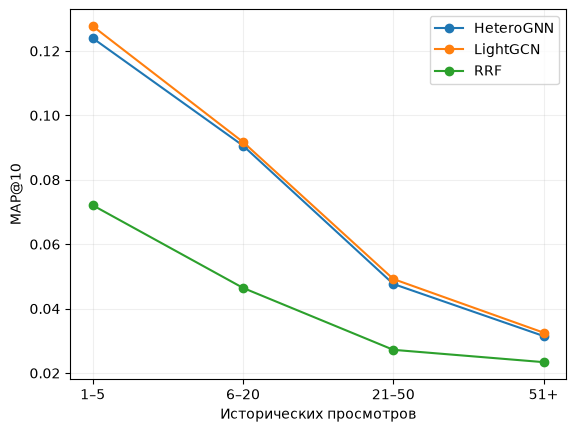

In [24]:
import matplotlib.pyplot as plt

for name, part in segments.groupby("model"):
    values = part.groupby("segment", observed=True)["map10"].mean().reindex(['1–5', '6–20', '21–50', '51+'])
    plt.plot(values.index, values, marker='o', label=name)

plt.xlabel('Исторических просмотров')
plt.ylabel('MAP@10')
plt.legend()
plt.grid(alpha=0.2)
plt.show()